In [1]:
%load_ext autoreload
%autoreload 2
import pandas as pd
import numpy as np
from src.config import *
from src.experiments import run_experiment, show
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA

In [2]:
train = pd.read_csv(BINARY_FEATURES_TRAIN_CSV)
feature_cols = [c for c in train.columns if c not in ("filename", "label")]
y = train["label"].values

groups = {
    "colour":  [c for c in feature_cols if c.startswith(("rgb_", "hsv_", "lab_", "hist_"))],
    "texture": [c for c in feature_cols if c.startswith(("lbp_", "glcm_"))],
}
all_results = []

### Baseline Experiment
Uses all the 232 features extracted from priority 1 features (global color and texture).

In [3]:
table, fitted_e0 = run_experiment("E0 all features", train[feature_cols].values, y)
all_results.append(table)
show(table)

[E0 all features] LogReg: balanced_accuracy = 0.831
[E0 all features] Random Forest: balanced_accuracy = 0.842
[E0 all features] HistGradBoost: balanced_accuracy = 0.847
[E0 all features] SVM (RBF): balanced_accuracy = 0.858
[E0 all features] XGBoost: balanced_accuracy = 0.851
[E0 all features] CatBoost: balanced_accuracy = 0.851


,experiment,model,accuracy,balanced_accuracy,sensitivity,specificity,auc
0,E0 all features,LogReg,0.831 ± 0.009,0.831 ± 0.009,0.836 ± 0.018,0.827 ± 0.015,0.904 ± 0.010
1,E0 all features,Random Forest,0.842 ± 0.014,0.842 ± 0.014,0.844 ± 0.023,0.840 ± 0.016,0.913 ± 0.009
2,E0 all features,HistGradBoost,0.847 ± 0.006,0.847 ± 0.005,0.853 ± 0.019,0.841 ± 0.013,0.918 ± 0.007
3,E0 all features,SVM (RBF),0.858 ± 0.009,0.858 ± 0.009,0.868 ± 0.011,0.848 ± 0.012,0.923 ± 0.010
4,E0 all features,XGBoost,0.851 ± 0.009,0.851 ± 0.009,0.856 ± 0.008,0.846 ± 0.020,0.922 ± 0.006
5,E0 all features,CatBoost,0.851 ± 0.012,0.851 ± 0.012,0.860 ± 0.009,0.842 ± 0.024,0.923 ± 0.008


### Experiment 1 - Color features VS Texture features
This experiment aims at trying to see if only one group of features is better than using both groups at the same time.

In [4]:
for group, cols in groups.items():
    table, _ = run_experiment(f"E1 {group} only", train[cols].values, y)
    all_results.append(table)
show(pd.concat(all_results[-2:]))

[E1 colour only] LogReg: balanced_accuracy = 0.810
[E1 colour only] Random Forest: balanced_accuracy = 0.828
[E1 colour only] HistGradBoost: balanced_accuracy = 0.826
[E1 colour only] SVM (RBF): balanced_accuracy = 0.838
[E1 colour only] XGBoost: balanced_accuracy = 0.833
[E1 colour only] CatBoost: balanced_accuracy = 0.841
[E1 texture only] LogReg: balanced_accuracy = 0.794
[E1 texture only] Random Forest: balanced_accuracy = 0.800
[E1 texture only] HistGradBoost: balanced_accuracy = 0.810
[E1 texture only] SVM (RBF): balanced_accuracy = 0.821
[E1 texture only] XGBoost: balanced_accuracy = 0.818
[E1 texture only] CatBoost: balanced_accuracy = 0.820


,experiment,model,accuracy,balanced_accuracy,sensitivity,specificity,auc
0,E1 colour only,LogReg,0.810 ± 0.010,0.810 ± 0.010,0.810 ± 0.016,0.810 ± 0.014,0.884 ± 0.007
1,E1 colour only,Random Forest,0.828 ± 0.014,0.828 ± 0.014,0.833 ± 0.015,0.823 ± 0.018,0.899 ± 0.010
2,E1 colour only,HistGradBoost,0.826 ± 0.013,0.826 ± 0.013,0.837 ± 0.019,0.815 ± 0.016,0.905 ± 0.008
3,E1 colour only,SVM (RBF),0.838 ± 0.011,0.838 ± 0.011,0.853 ± 0.017,0.822 ± 0.020,0.904 ± 0.008
4,E1 colour only,XGBoost,0.833 ± 0.008,0.833 ± 0.008,0.842 ± 0.013,0.824 ± 0.010,0.910 ± 0.008
5,E1 colour only,CatBoost,0.841 ± 0.011,0.841 ± 0.011,0.854 ± 0.016,0.828 ± 0.014,0.909 ± 0.008
0,E1 texture only,LogReg,0.794 ± 0.018,0.794 ± 0.018,0.807 ± 0.012,0.780 ± 0.027,0.872 ± 0.015
1,E1 texture only,Random Forest,0.800 ± 0.013,0.800 ± 0.013,0.810 ± 0.015,0.790 ± 0.020,0.879 ± 0.010
2,E1 texture only,HistGradBoost,0.811 ± 0.009,0.810 ± 0.009,0.822 ± 0.008,0.799 ± 0.018,0.888 ± 0.006
3,E1 texture only,SVM (RBF),0.821 ± 0.009,0.821 ± 0.009,0.836 ± 0.010,0.805 ± 0.015,0.897 ± 0.010


### Experiment 2 - SelectKBest (top 50 / top 100)
Keep the k features that best separate the classes on their own (ANOVA F-test).

In [5]:
for k in [50, 100]:
    table, _ = run_experiment(f"E2 top-{k}", train[feature_cols].values, y,
                              selector=SelectKBest(f_classif, k=k))
    all_results.append(table)
show(pd.concat(all_results[-2:]))

[E2 top-50] LogReg: balanced_accuracy = 0.802
[E2 top-50] Random Forest: balanced_accuracy = 0.818
[E2 top-50] HistGradBoost: balanced_accuracy = 0.808
[E2 top-50] SVM (RBF): balanced_accuracy = 0.824
[E2 top-50] XGBoost: balanced_accuracy = 0.818
[E2 top-50] CatBoost: balanced_accuracy = 0.821
[E2 top-100] LogReg: balanced_accuracy = 0.821
[E2 top-100] Random Forest: balanced_accuracy = 0.838
[E2 top-100] HistGradBoost: balanced_accuracy = 0.842
[E2 top-100] SVM (RBF): balanced_accuracy = 0.853
[E2 top-100] XGBoost: balanced_accuracy = 0.846
[E2 top-100] CatBoost: balanced_accuracy = 0.849


,experiment,model,accuracy,balanced_accuracy,sensitivity,specificity,auc
0,E2 top-50,LogReg,0.802 ± 0.012,0.802 ± 0.013,0.809 ± 0.010,0.794 ± 0.019,0.868 ± 0.012
1,E2 top-50,Random Forest,0.818 ± 0.013,0.818 ± 0.013,0.827 ± 0.015,0.809 ± 0.017,0.886 ± 0.009
2,E2 top-50,HistGradBoost,0.808 ± 0.013,0.808 ± 0.013,0.816 ± 0.014,0.800 ± 0.016,0.883 ± 0.007
3,E2 top-50,SVM (RBF),0.825 ± 0.014,0.824 ± 0.014,0.835 ± 0.015,0.813 ± 0.021,0.893 ± 0.011
4,E2 top-50,XGBoost,0.818 ± 0.009,0.818 ± 0.009,0.825 ± 0.012,0.811 ± 0.014,0.887 ± 0.008
5,E2 top-50,CatBoost,0.821 ± 0.011,0.821 ± 0.011,0.825 ± 0.010,0.816 ± 0.014,0.890 ± 0.010
0,E2 top-100,LogReg,0.821 ± 0.012,0.821 ± 0.012,0.820 ± 0.018,0.822 ± 0.021,0.893 ± 0.010
1,E2 top-100,Random Forest,0.838 ± 0.011,0.838 ± 0.011,0.839 ± 0.020,0.836 ± 0.014,0.907 ± 0.009
2,E2 top-100,HistGradBoost,0.842 ± 0.012,0.842 ± 0.012,0.851 ± 0.020,0.833 ± 0.014,0.914 ± 0.007
3,E2 top-100,SVM (RBF),0.854 ± 0.012,0.853 ± 0.012,0.865 ± 0.015,0.842 ± 0.014,0.915 ± 0.009


### Experiment 3 - PCA for feature reduction
Compress all features into fewer uncorrelated components. We need to explore which is a good % of variance that we want to preserve.

80% variance -> 16 components
90% variance -> 31 components
95% variance -> 49 components
99% variance -> 90 components


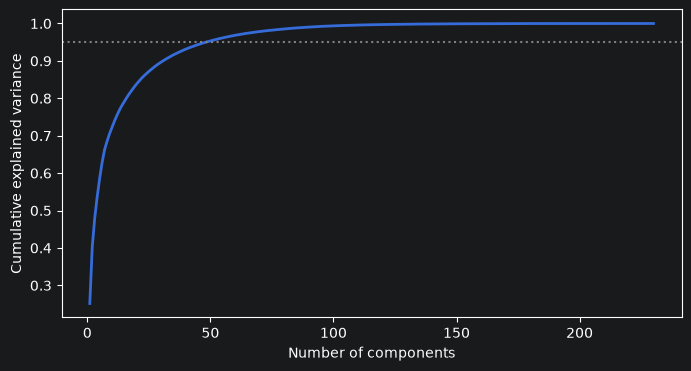

In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

X_scaled = StandardScaler().fit_transform(train[feature_cols].values)
cumulative = np.cumsum(PCA().fit(X_scaled).explained_variance_ratio_)

for t in [0.80, 0.90, 0.95, 0.99]:
    print(f"{t:.0%} variance -> {np.searchsorted(cumulative, t) + 1} components")

plt.figure(figsize=(8, 4))
plt.plot(np.arange(1, len(cumulative) + 1), cumulative, linewidth=2)
plt.axhline(0.95, color="gray", linestyle=":")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.show()

In [7]:
table, _ = run_experiment("E3 PCA 95%", train[feature_cols].values, y,
                          selector=PCA(n_components=0.95, random_state=RANDOM_STATE))
all_results.append(table)
show(table)

[E3 PCA 95%] LogReg: balanced_accuracy = 0.804
[E3 PCA 95%] Random Forest: balanced_accuracy = 0.832
[E3 PCA 95%] HistGradBoost: balanced_accuracy = 0.830
[E3 PCA 95%] SVM (RBF): balanced_accuracy = 0.852
[E3 PCA 95%] XGBoost: balanced_accuracy = 0.839
[E3 PCA 95%] CatBoost: balanced_accuracy = 0.842


,experiment,model,accuracy,balanced_accuracy,sensitivity,specificity,auc
0,E3 PCA 95%,LogReg,0.804 ± 0.014,0.804 ± 0.014,0.807 ± 0.012,0.800 ± 0.017,0.878 ± 0.009
1,E3 PCA 95%,Random Forest,0.831 ± 0.011,0.832 ± 0.011,0.824 ± 0.016,0.839 ± 0.013,0.905 ± 0.010
2,E3 PCA 95%,HistGradBoost,0.831 ± 0.015,0.830 ± 0.014,0.837 ± 0.024,0.824 ± 0.014,0.903 ± 0.009
3,E3 PCA 95%,SVM (RBF),0.853 ± 0.009,0.852 ± 0.009,0.863 ± 0.015,0.842 ± 0.016,0.916 ± 0.009
4,E3 PCA 95%,XGBoost,0.839 ± 0.010,0.839 ± 0.010,0.846 ± 0.017,0.831 ± 0.010,0.911 ± 0.007
5,E3 PCA 95%,CatBoost,0.842 ± 0.006,0.842 ± 0.007,0.846 ± 0.015,0.838 ± 0.018,0.910 ± 0.009


### Summary of the best models for each experiment

In [8]:
results = pd.concat(all_results, ignore_index=True)
results.to_csv(RESULTS_DIR / "exp1_feature_selection.csv", index=False)

best_per_experiment = results.loc[results.groupby("experiment")["balanced_accuracy"].idxmax()]
show(best_per_experiment.sort_values("balanced_accuracy", ascending=False))

,experiment,model,accuracy,balanced_accuracy,sensitivity,specificity,auc
3,E0 all features,SVM (RBF),0.858 ± 0.009,0.858 ± 0.009,0.868 ± 0.011,0.848 ± 0.012,0.923 ± 0.010
27,E2 top-100,SVM (RBF),0.854 ± 0.012,0.853 ± 0.012,0.865 ± 0.015,0.842 ± 0.014,0.915 ± 0.009
33,E3 PCA 95%,SVM (RBF),0.853 ± 0.009,0.852 ± 0.009,0.863 ± 0.015,0.842 ± 0.016,0.916 ± 0.009
11,E1 colour only,CatBoost,0.841 ± 0.011,0.841 ± 0.011,0.854 ± 0.016,0.828 ± 0.014,0.909 ± 0.008
21,E2 top-50,SVM (RBF),0.825 ± 0.014,0.824 ± 0.014,0.835 ± 0.015,0.813 ± 0.021,0.893 ± 0.011
15,E1 texture only,SVM (RBF),0.821 ± 0.009,0.821 ± 0.009,0.836 ± 0.010,0.805 ± 0.015,0.897 ± 0.010


From these experiments the conclusion that we can extract is that **SVM with all the features** still outperforms the models when doing feature reduction/selection. Having said that, we can conclude that feature selection is not helping the algorithm improve.

---

In [9]:
table_check, _ = run_experiment("check new experiments.py", train[feature_cols].values, y,
                                only=["CatBoost"])
show(table_check)

[check new experiments.py] CatBoost: balanced_accuracy = 0.851


,experiment,model,accuracy,balanced_accuracy,sensitivity,specificity,auc
0,check new experiments.py,CatBoost,0.851 ± 0.012,0.851 ± 0.012,0.860 ± 0.009,0.842 ± 0.024,0.923 ± 0.008
